# P14: Exploratory analysis

Descriptive only: no causal claims and no models of the post-period. Computations live in `src/sod/eda.py` (tested in `tests/test_eda.py`); this notebook shows them.

Pre-period = 2017-01 to 2022-11 (the pre-registered synthetic-control window). COVID months (2020-03 to 2020-06) are left out of slope and seasonality fits. Data: P13 panels.

In [1]:
import pandas as pd
from IPython.display import Image, display
from sod import config, eda

summary = eda.run()  # writes report/figures/eda_*.png and report/qa/eda_summary.json
m = eda.load_month()

## 1. Long-run trends, indexed to 2019 = 100

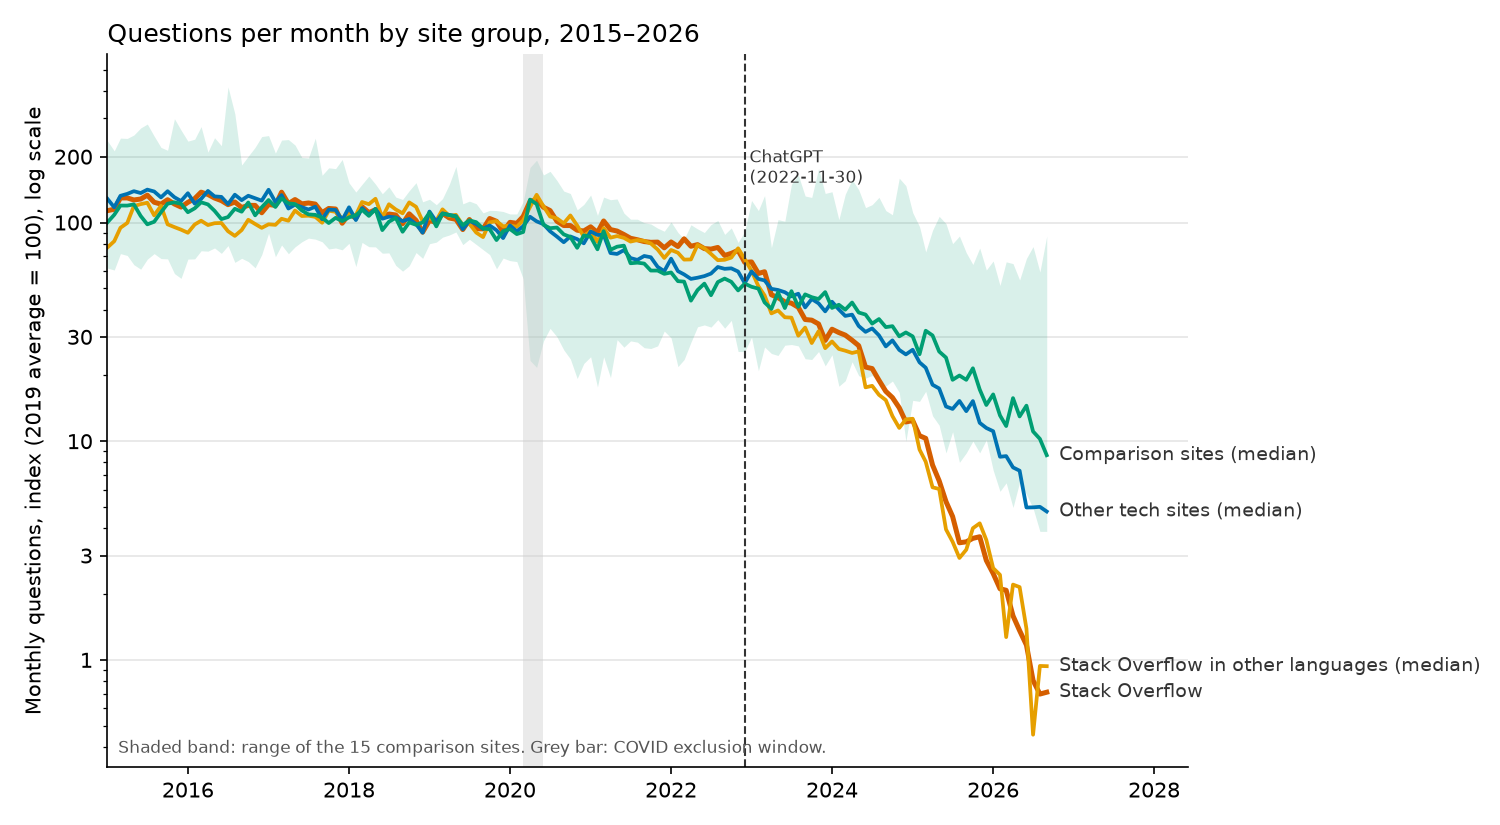

context         11.95
donor            8.63
so_language      0.94
tech_exposed     4.77
treated          0.71
Name: 2026-09-01, dtype: float64

In [2]:
display(Image(config.FIGURE_DIR / 'eda_trends_indexed.png'))
pd.Series(summary['index_2019_100_latest_full_month'], name=summary['latest_full_month'])

## 2. Seasonality: weekday, month of year, holidays

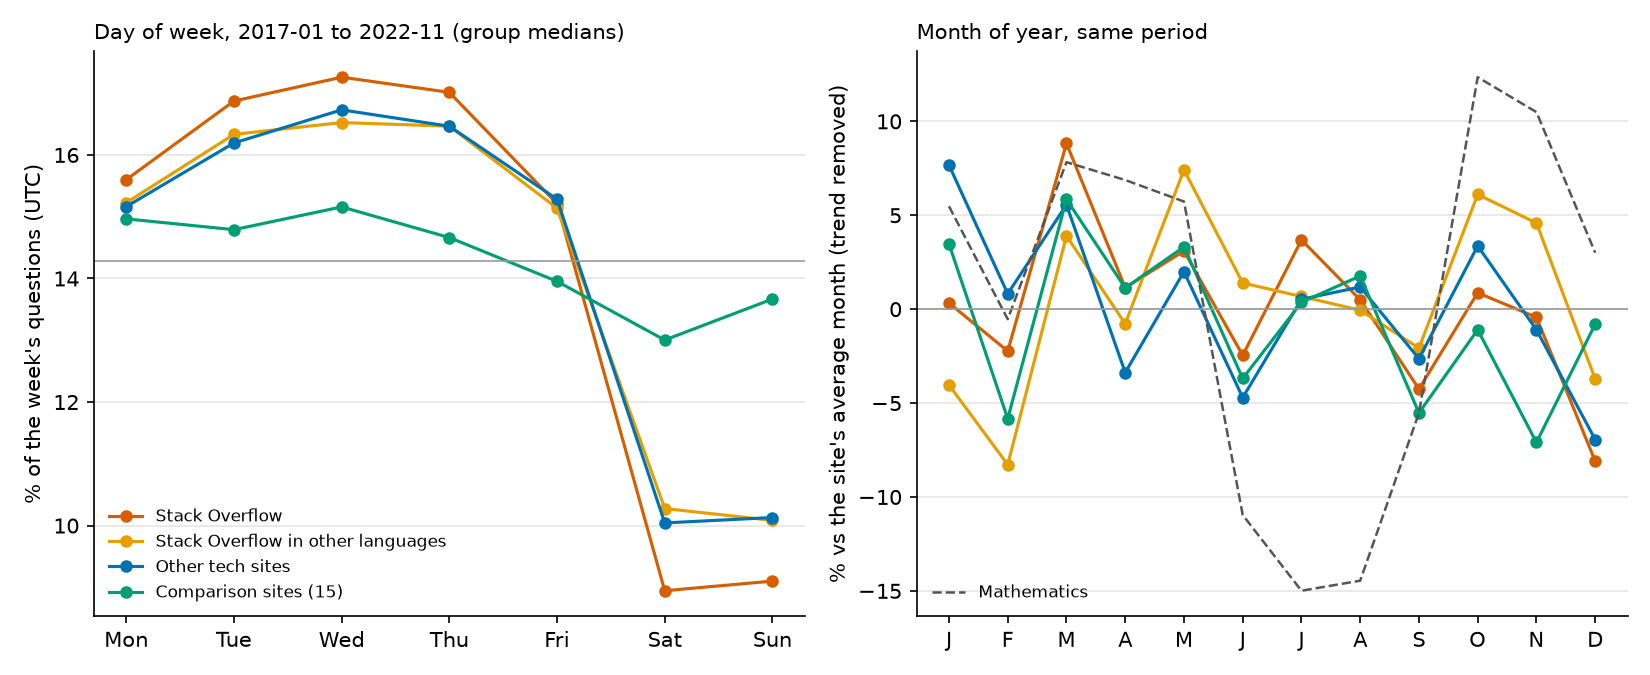

,weekend share 2017-22,weekend share 2025-26
context,0.1787,0.1446
donor,0.2644,0.2713
so_language,0.2043,0.2183
tech_exposed,0.2017,0.2010
treated,0.1805,0.1766


In [3]:
display(Image(config.FIGURE_DIR / 'eda_seasonality.png'))
pd.DataFrame({'weekend share 2017-22': summary['weekend_share_pre'], 'weekend share 2025-26': summary['weekend_share_2025_26']})

In [4]:
pd.DataFrame(summary['holiday_ratio_median']).T.rename(columns=lambda c: c + ' week / early-December weeks')

,christmas week / early-December weeks,new_year week / early-December weeks
context,0.548,0.920
donor,0.891,0.905
so_language,0.709,0.677
tech_exposed,0.777,0.897
treated,0.670,0.758


## 3. Each site's pre-2022 trend

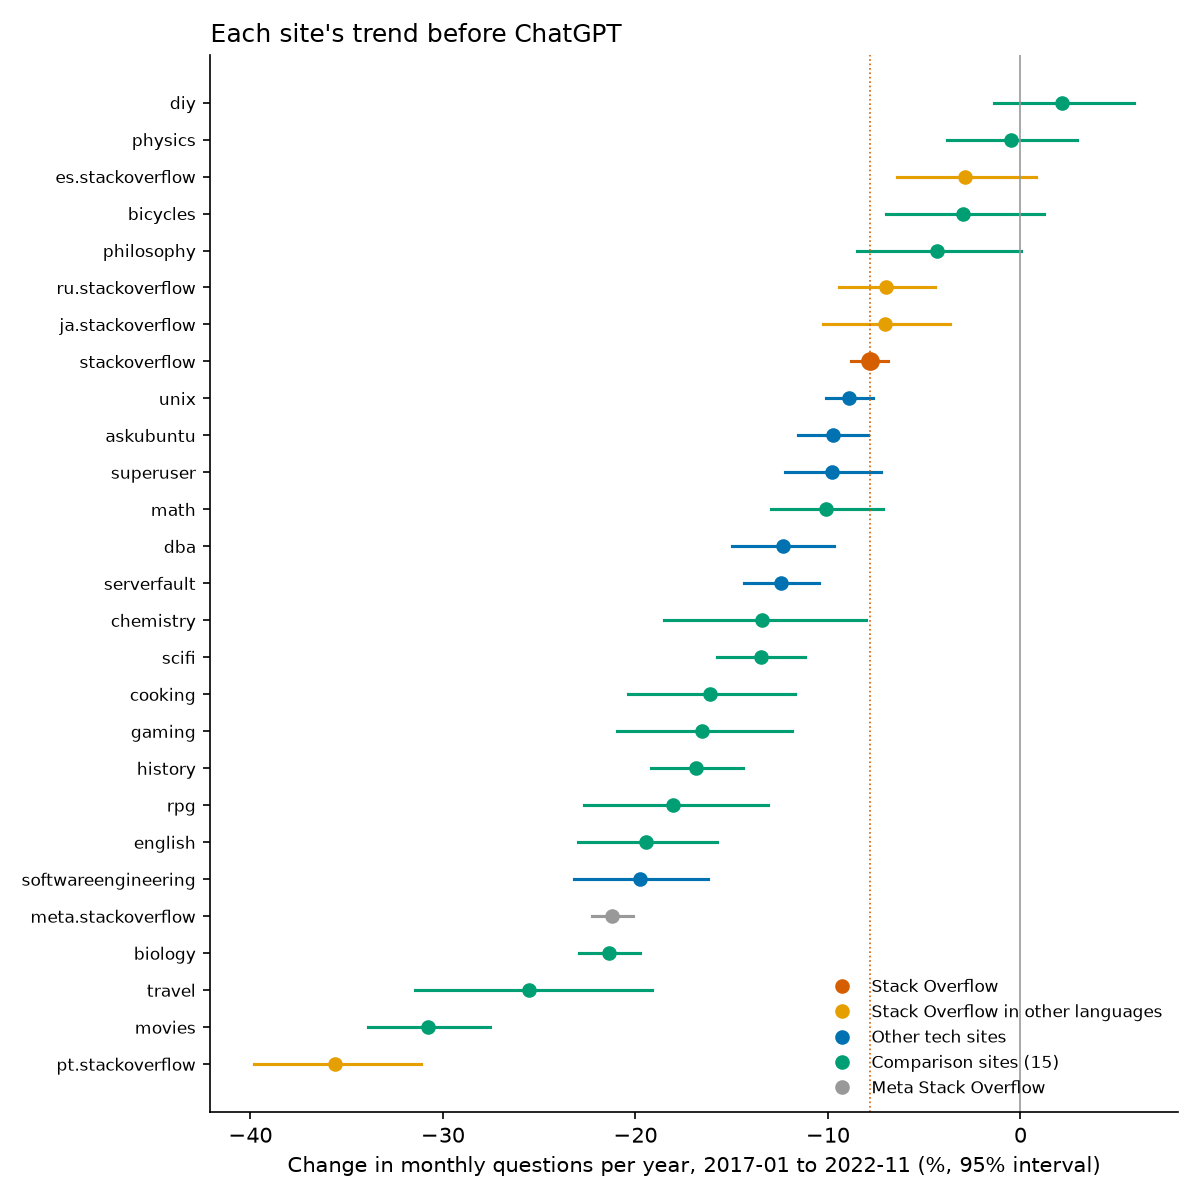

,site,group,pct_per_year,low,high,n_months
0,pt.stackoverflow.com,so_language,-35.6,-39.8,-31.1,67
1,movies.stackexchange.com,donor,-30.8,-33.9,-27.6,67
2,travel.stackexchange.com,donor,-25.5,-31.4,-19.1,67
3,biology.stackexchange.com,donor,-21.4,-22.9,-19.8,67
4,meta.stackoverflow.com,context,-21.2,-22.2,-20.1,67
5,softwareengineering.stackexchange.com,tech_exposed,-19.8,-23.2,-16.2,67
6,english.stackexchange.com,donor,-19.4,-23.0,-15.8,67
7,rpg.stackexchange.com,donor,-18.0,-22.7,-13.1,67
8,history.stackexchange.com,donor,-16.8,-19.2,-14.4,67
9,gaming.stackexchange.com,donor,-16.6,-21.0,-11.9,67


In [5]:
display(Image(config.FIGURE_DIR / 'eda_pre_slopes.png'))
pd.DataFrame(summary['pre_slopes_pct_per_year']).round(1)

### Did the decline speed up before ChatGPT?
Slopes over 2017–2019 vs 2020-07 to 2022-11 (after the COVID bump).

In [6]:
import numpy as np
def slope(g, a, b):
    g = g[(g.period >= a) & (g.period <= b)]
    t = (g.period - g.period.min()).dt.days / 365.25
    return 100 * (np.exp(np.polyfit(t, np.log(g.questions), 1)[0]) - 1)
acc = pd.DataFrame([(eda.short(s), g.group.iloc[0], slope(g, '2017-01-01', '2019-12-01'), slope(g, '2020-07-01', '2022-11-01')) for s, g in m.groupby('site')],
                   columns=['site', 'group', '2017-19 %/yr', '2020-07..2022-11 %/yr']).round(1)
display(acc.groupby('group')[['2017-19 %/yr', '2020-07..2022-11 %/yr']].median())
acc

,2017-19 %/yr,2020-07..2022-11 %/yr
group,,
context,-23.80,-21.1
donor,-6.80,-25.8
so_language,-0.95,-18.3
tech_exposed,-10.00,-18.0
treated,-9.10,-14.1


,site,group,2017-19 %/yr,2020-07..2022-11 %/yr
0,askubuntu,tech_exposed,-12.2,-19.3
1,bicycles,donor,-2.4,-25.0
2,biology,donor,-26.1,-28.6
3,chemistry,donor,-12.8,-32.8
4,cooking,donor,-3.8,-28.8
5,dba,tech_exposed,-3.4,-12.1
6,diy,donor,8.3,-17.0
7,english,donor,-12.9,-35.2
8,es.stackoverflow,so_language,6.1,-14.7
9,gaming,donor,-17.4,-30.8


## 4. How the comparison sites tracked Stack Overflow before 2022
Equal-weight average only: the weighted synthetic control is fitted in P17.

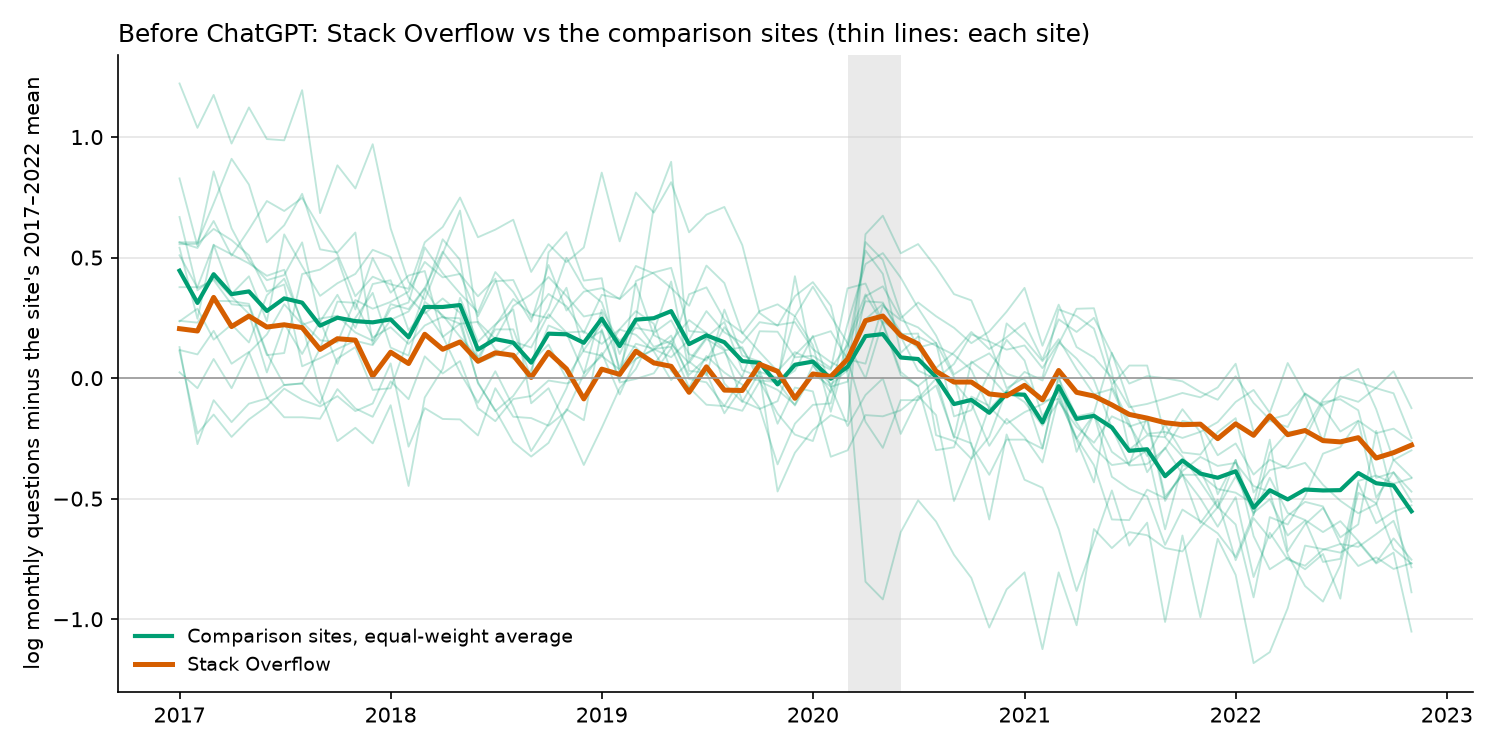

{'equal_weight_rmspe_log': 0.15007875482974387,
 'gap_start_log': -0.12144798672633245,
 'gap_end_log': 0.21252392064100267}

In [7]:
display(Image(config.FIGURE_DIR / 'eda_pre_tracking.png'))
{k: summary[k] for k in ('equal_weight_rmspe_log', 'gap_start_log', 'gap_end_log')}

In [8]:
pd.Series(summary['donor_change_corr'], name='corr. of deseasonalised monthly changes with Stack Overflow')

physics.stackexchange.com       0.537
math.stackexchange.com          0.496
biology.stackexchange.com       0.400
scifi.stackexchange.com         0.338
gaming.stackexchange.com        0.287
cooking.stackexchange.com       0.268
chemistry.stackexchange.com     0.249
bicycles.stackexchange.com      0.228
movies.stackexchange.com        0.215
english.stackexchange.com       0.201
rpg.stackexchange.com           0.192
travel.stackexchange.com        0.185
diy.stackexchange.com           0.146
history.stackexchange.com       0.017
philosophy.stackexchange.com   -0.002
Name: corr. of deseasonalised monthly changes with Stack Overflow, dtype: float64